#Introduction to Linear Algebra and the world of probablitites

In this work-sheet, we shall do two activities. First of all we shall check the power of SVD. Then we shall check how may we generate data from an arbitrary distribution (given that we have the ability to generate data from a uniform distribution).

##Singular Value Decomposition
Lets load an image and try to do it's SVD.

Please note the way to access an image from your Google drive. Change the code accordingly (and load an image in your Google drive) to access to your own image!

Mark that we shall be using PIL's Image library, a useful set of powerful algorithms for image processing.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import time

from PIL import Image

In [2]:
# Load the Drive helper and mount
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Lets load the image and convert that to a gray-scale version (so that we can treat it just like a 2D matrix). What will happen if its not gray-scale?







Mark how we have used the command $matrix$ to generate a matrix from the image!

A grayscale image has one value per pixel, so it is an m × n matrix and SVD can be applied to it directly. A color (RGB) image has three values per pixel, so it is an m × n × 3 array, not a single matrix. SVD must then be performed separately for each channel (R, G, B) and the results combined, which costs about three times more computation and memory. Converting to grayscale (convert('L')) merges the three channels into one using fixed weights (L = 0.299 R + 0.587 G + 0.114 B), which simplifies the task but loses color information.

The brightness values of the grayscale image are read as a vector (getdata), reshaped to (height × width) and stored as an np.matrix, on which SVD and matrix multiplication can be performed.

In [8]:
img = Image.open("/content/5983172181485096831.jpg")
imggray = img.convert('L')

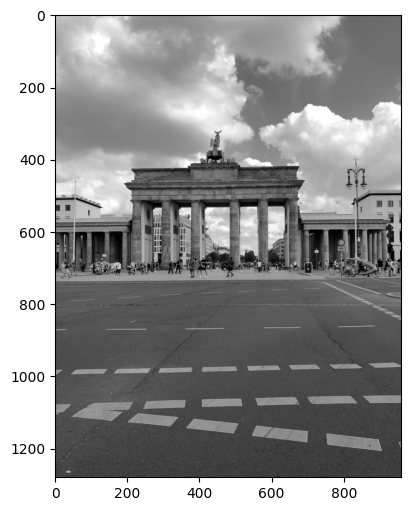

In [9]:
imgmat = np.array(list(imggray.getdata(band=0)), float)
imgmat.shape = (imggray.size[1], imggray.size[0])
imgmat = np.matrix(imgmat)
plt.figure(figsize=(9,6))
plt.imshow(imgmat, cmap='gray')

###SVD

We can directly use the $svd$ command from Numpy to operate SVD on the matrix.

Lets first check how the image will look if we only use a single vector to reconstruct the image.

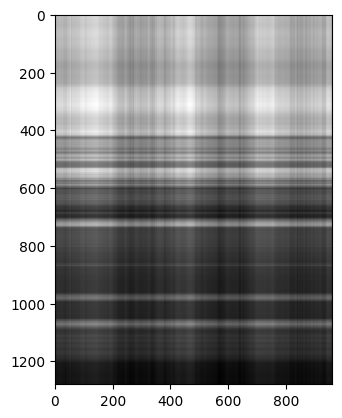

In [10]:
U, sigma, V = np.linalg.svd(imgmat)
reconstimg = np.matrix(U[:, :1]) * np.diag(sigma[:1]) * np.matrix(V[:1, :])
plt.imshow(reconstimg, cmap='gray');

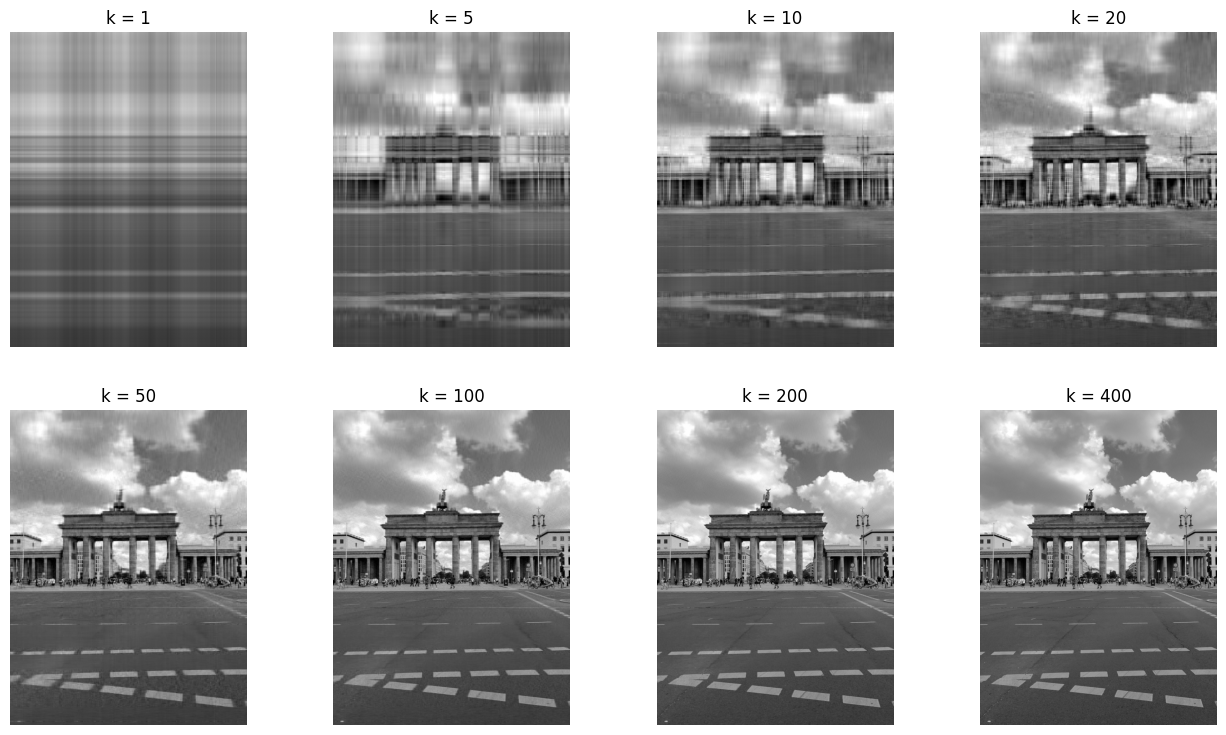

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(16, 9))
for ax, k in zip(axes.flat, [1, 5, 10, 20, 50, 100, 200, 400]):
    R = np.array(U[:, :k] @ np.diag(sigma[:k]) @ V[:k, :])
    ax.imshow(R, cmap='gray', vmin=0, vmax=255)
    ax.set_title(f"k = {k}"); ax.axis('off')
plt.show()


Now lets check how does the sigma vector look like.

What do you observe? How many vecotrs can we use to get a decent reconstruction of the image?
What will happen if we omit the first 1-2 vectors (corresponding to the largest eigen values)?



(1280, 1280)
(960,)


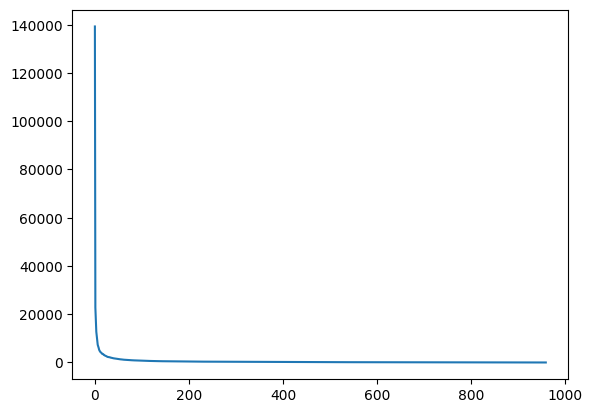

In [17]:
print(U.shape)
print(sigma.shape)
plt.plot(sigma)

The singular values drop extremely fast: σ₁ ≈ 1.4·10⁵, σ₂ ≈ 2·10⁴, and after a few dozen values they are close to zero. Most of the information is therefore stored in the first few components. A reconstruction with about 50-100 components (≈7% of all ~960) already gives a decent image: the overall scene, clouds, columns and road markings are preserved, only fine details are blurred. If the first 1–2 components (largest singular values) are omitted, the image loses its overall brightness and large-scale structure, since these components carry most of the energy; mainly edges and fine details remain, and the reconstruction is far worse than one with the same number of the largest components.

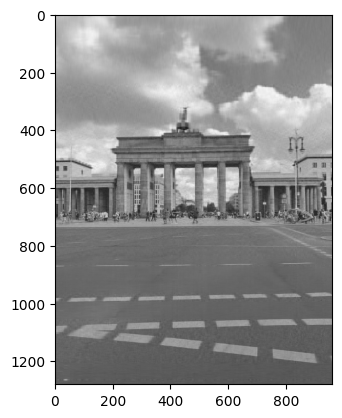

In [12]:
i = 70
j = 0
reconstimg = np.matrix(U[:, j:i]) * np.diag(sigma[j:i]) * np.matrix(V[j:i, :])
plt.imshow(reconstimg, cmap='gray');

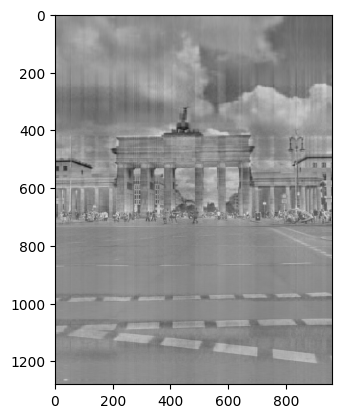

In [13]:
i = 70
j = 2
reconstimg = np.matrix(U[:, j:i]) * np.diag(sigma[j:i]) * np.matrix(V[j:i, :])
plt.imshow(reconstimg, cmap='gray');



When the first two components (largest singular values) are omitted, the reconstruction loses the overall brightness and large-scale structure: the image becomes flat and gray, the sky is no longer bright and the clouds lose their contrast. Mostly edges and fine details remain (columns of the gate, road markings, people), and vertical streaking artifacts appear. This shows that the first components carry most of the energy (average intensity and coarse shapes), while later components describe progressively finer details. Therefore, the largest singular values cannot be skipped if we want a faithful reconstruction.